# Image Super-Resolution

A neural field can upsample an image: it is fitted to the low-resolution (LR)
pixels through the degradation that made them, and rendered at the high
resolution (HR). This notebook recovers image 0882 of the DIV2K validation set
from its 4× bicubic downsampling, the benchmark's degradation, with fields of
about 500k parameters each. No model sees the HR image, which only scores the
results: as is standard, PSNR and SSIM on the luma (Y) channel after shaving a
4-pixel border, and LPIPS on RGB. The fields are FUTON, with a sinc and a
Lanczos basis, and four representative baselines of the benchmark: SIREN and
FINER (periodic activations), Instant-NGP (a hash grid) and TensoRF (a grid
factorization); bicubic interpolation is the reference. Every setting is that
of `configs/super_resolution.yaml`, which holds every model of the benchmark.

## Setup

In [1]:
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib.ticker import (
    FixedLocator,
    MaxNLocator,
    MultipleLocator,
    NullFormatter,
    StrMethodFormatter,
)
from matplotlib_inline.backend_inline import set_matplotlib_formats
import torch.nn.functional as F
from PIL import Image
from torchvision.transforms.functional import pil_to_tensor

import neurofield as nf

set_matplotlib_formats("retina")  # sharp figures on high-resolution screens
sns.set_theme(
    context="notebook", style="whitegrid", font_scale=0.85, rc={"grid.color": ".92"}
)

colorblind = sns.color_palette("colorblind")
# FUTON in black, its Lanczos basis dashed; the periodic activations in warm
# hues and the grids in cool ones.
PALETTE = {
    "FUTON (sinc)": "black",
    "FUTON (Lanczos)": "black",
    "RFF": colorblind[4],
    "SIREN": colorblind[1],
    "FINER": colorblind[3],
    "Instant-NGP": colorblind[2],
    "TensoRF": colorblind[0],
}
DASHES = {model: (4, 2) if model == "FUTON (Lanczos)" else "" for model in PALETTE}
# seaborn's own markers, each fixed to a model as its colour is
MARKERS = dict(zip(PALETTE, ["o", "X", (4, 0, 45), "P", (4, 0, 0), (4, 1, 0), "^"]))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


The plotting helpers: training time on a log axis, the metric on whole
decibels or half points, a summary table, images side by side, and
reconstructions above their errors.

In [2]:
NICE = [1, 2, 5, 10]  # tick steps: 1, 2 or 5 times a power of ten


def time_axis(ax, times):
    """Training time on a log axis, ticked 1, 2, 5, 10, ... in plain numbers."""
    low, high = times.min() / 1.1, times.max() * 1.1
    ax.set(xscale="log", xlim=(low, high), xlabel="Training time (s)")
    for subs in ((1, 2, 5), (1,)):
        ticks = [m * 10.0**k for k in range(-3, 6) for m in subs]
        ticks = [tick for tick in ticks if low <= tick <= high]
        if len(ticks) <= 7:
            break
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())


def metric_axis(ax, metric, low, high):
    """The metric's axis over [low, high]: whole decibels for a PSNR, half
    points for an IoU, which cannot pass 100."""
    if metric == "IoU (%)":
        low = np.floor(2 * low) / 2
        ax.set_ylim(low, min(max(np.ceil(2 * high) / 2, low + 0.5), 100))
        ax.yaxis.set_major_locator(MultipleLocator(0.5))
    else:
        low = np.floor(low)
        ax.set_ylim(low, max(np.ceil(high), low + 1))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=NICE, integer=True))


def table(summary, formats, better):
    """The summary, each column in its format and, in each column of
    ``better`` ("higher" or "lower"), the best value bold and the second
    underlined."""

    def marks(column):
        rank = column.rank(method="min", ascending=better[column.name] == "lower")
        looks = {1: "font-weight: bold", 2: "text-decoration: underline"}
        return [looks.get(r, "") for r in rank]

    return (
        summary.style.format(formats, na_rep="")
        .apply(marks, subset=list(better))
        .hide(axis="index")
    )


def show(panels, ncols, width=11, **imshow):
    """Images side by side under their titles, in rows of ``ncols``, each
    drawn at the size of the first."""
    height, side = panels[0][1].shape[:2]
    nrows = -(-len(panels) // ncols)
    room = 0.45 if any("\n" in title for title, _ in panels) else 0.3
    fig, axes = plt.subplots(
        nrows,
        ncols,
        squeeze=False,
        layout="constrained",
        figsize=(width, nrows * (width / ncols * height / side + room)),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes.flat, panels):
        ax.imshow(image, interpolation="nearest", **imshow)
        ax.set_title(title, fontsize=9)
    return fig


def compare(panels, label, width=11):
    """The reference and the reconstructions in a row under their titles
    (``panels``, the reference first), and beneath each reconstruction its
    absolute error, averaged over the colour channels; the errors share one
    scale, which saturates at their 99th percentile, and its colour bar
    stands beneath the reference."""
    reference = panels[0][1].astype(float)
    errors = [np.abs(image - reference).mean(-1) for _, image in panels[1:]]
    height, side = reference.shape[:2]
    ncols = len(panels)
    fig, axes = plt.subplots(
        2,
        ncols,
        layout="constrained",
        figsize=(width, 2 * width / ncols * height / side + 0.45),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes[0], panels):
        ax.imshow(image, interpolation="nearest")
        ax.set_title(title, fontsize=9)
    vmax = np.percentile(np.concatenate([error.ravel() for error in errors]), 99)
    for ax, error in zip(axes[1, 1:], errors):
        maps = ax.imshow(
            error, cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
    bar = fig.colorbar(maps, cax=axes[1, 0].inset_axes([0.8, 0.04, 0.07, 0.92]))
    bar.ax.yaxis.set_ticks_position("left")
    bar.ax.yaxis.set_label_position("left")
    bar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=NICE))
    bar.ax.tick_params(labelsize=8)
    bar.set_label(label, fontsize=9)
    bar.outline.set_visible(False)
    return fig

## Data

The HR image and its LR version, with the region that the comparison at the end
magnifies: the butterfly's head, whose antennae are thinner than an LR pixel.

HR: 1356 x 2040 pixels, LR: 339 x 510


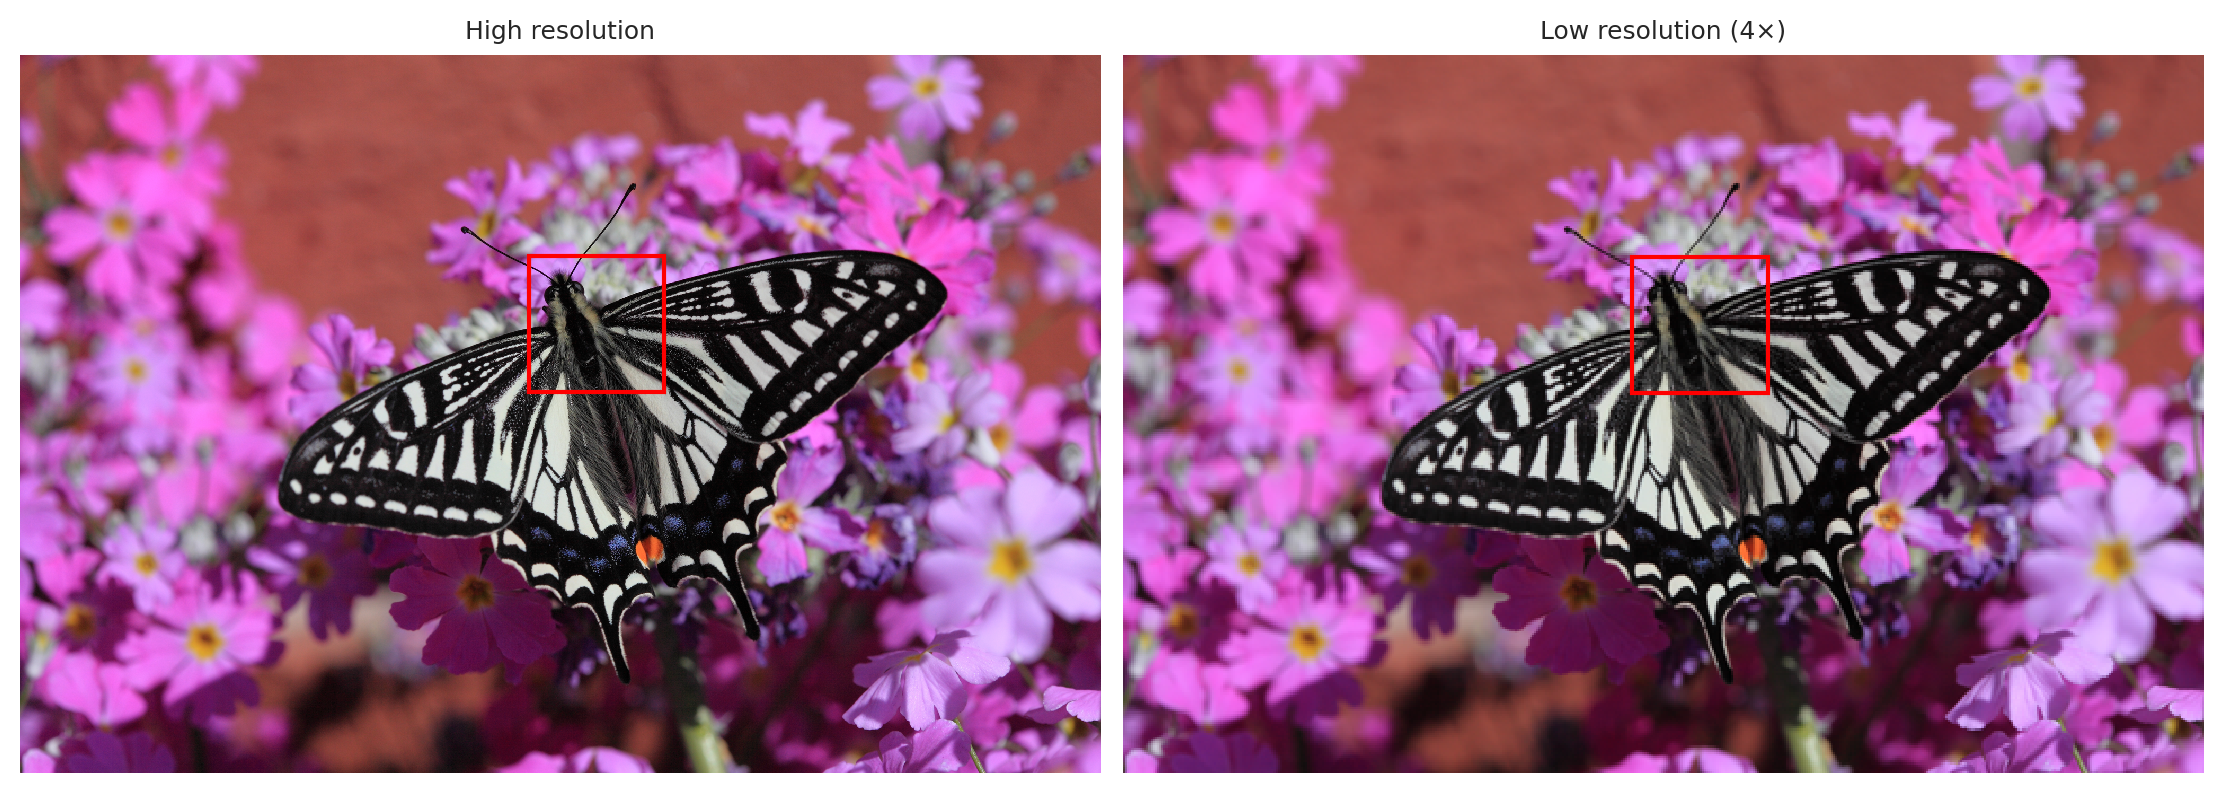

In [3]:
SCALE = 4
HR_PATH = "../data/DIV2K/DIV2K_valid_HR/0882.png"
LR_PATH = f"../data/DIV2K/DIV2K_valid_LR_bicubic/X{SCALE}/0882x{SCALE}.png"
CROP = (slice(380, 636), slice(960, 1216))  # rows and columns of the HR image

image_hr, image_lr = (Image.open(path).convert("RGB") for path in (HR_PATH, LR_PATH))
original, observed = pil_to_tensor(image_hr), pil_to_tensor(image_lr)  # uint8 (C, H, W)
(H, W), (h, w) = original.shape[1:], observed.shape[1:]
print(f"HR: {H} x {W} pixels, LR: {h} x {w}")

fig = show(
    [
        ("High resolution", np.asarray(image_hr)),
        (f"Low resolution ({SCALE}×)", np.asarray(image_lr)),
    ],
    ncols=2,
)
for ax, scale in zip(fig.axes, (1, SCALE)):
    rows, columns = (slice(s.start // scale, s.stop // scale) for s in CROP)
    box = plt.Rectangle(
        (columns.start, rows.start),
        columns.stop - columns.start,
        rows.stop - rows.start,
    )
    ax.add_patch(box).set(fill=False, edgecolor="red", linewidth=1.5)
plt.show()

## Forward Model

Antialiased bicubic downsampling, which reproduces the benchmark's MATLAB
`imresize`, is linear and separable: one matrix per axis describes it exactly,
borders included, and resizing the rows of an identity image writes that matrix
out. Each of its rows has at most `4 * SCALE` nonzero taps, the footprint of one
LR pixel along the axis.

In [4]:
def resize_matrix(size_in, size_out, mode="bicubic", antialias=True):
    """The ``(size_out, size_in)`` matrix of ``F.interpolate`` along one axis."""
    identity = torch.eye(size_in, device=device)[None, None]
    size = (size_out, size_in)
    return F.interpolate(identity, size=size, mode=mode, antialias=antialias)[0, 0]


def downsample(image, kernels):
    """Apply one kernel per axis: ``(..., H, W, C)`` to ``(..., h, w, C)``."""
    return torch.einsum("...il,...lmc,...jm->...ijc", kernels[0], image, kernels[1])


kernels = [resize_matrix(H, h), resize_matrix(W, w)]  # (h, H) and (w, W)

# The forward model applied to the HR image gives the benchmark's LR image.
simulated = downsample(original.movedim(0, -1).float().to(device), kernels)
simulated = simulated.round().clamp(0, 255).movedim(-1, 0).cpu()
fidelity = nf.psnr(simulated, observed, data_range=255)
print(f"Taps per LR pixel and axis: {int((kernels[0] != 0).sum(1).max())}")
print(f"Forward model against the LR image: {fidelity:.2f} dB")

Taps per LR pixel and axis: 16
Forward model against the LR image: 57.72 dB


## Minibatches

`SuperResolutionDataset` draws random blocks of LR pixels that cover a share
`subsample` of the LR image, and returns the HR coordinates under their
kernels, the kernel rows, and the LR pixels. Neighbouring LR pixels share most
of their footprint, so a block needs far fewer field evaluations per pixel
than single pixels do: 30 in an 8 × 8 block against 256 alone. The loss
renders each footprint, downsamples it along both axes, and takes the mean
absolute error against the LR pixels, the usual loss in super-resolution.

In [5]:
class SuperResolutionDataset(nf.ImageCoordinateDataset):
    """LR pixels as targets, the HR coordinates under their kernels as inputs.

    Items hold ``input``, the HR coordinates of each block's footprint, of
    shape ``(B, L, L, 2)``; ``weight_y`` and ``weight_x``, the kernel rows of
    each block on its footprint, of shape ``(B, block, L)``; and ``target``,
    the LR pixels in ``[-1, 1]``, of shape ``(B, block, block, C)``.
    """

    def __init__(self, image, kernels, subsample=1.0, block=8):
        device = kernels[0].device
        self.original = self.load(image, mode="RGB")  # uint8 (C, h, w)
        self.id = Path(image).stem
        self.kernels, self.subsample, self.block = kernels, subsample, block
        self.grid_size = tuple(kernel.shape[1] for kernel in kernels)  # (H, W)
        self.input = self.create_input().to(device)  # HR coordinates, (H, W, 2)
        self.target = self.preprocess(self.original).to(device)  # LR pixels, (h, w, C)

        # The first tap of each kernel row, and the footprint of a block along one axis.
        self.first = [(kernel != 0).int().argmax(1) for kernel in kernels]
        taps = max(int((kernel != 0).sum(1).max()) for kernel in kernels)
        scale = self.grid_size[0] // self.target.shape[0]
        self.length = scale * (block - 1) + taps

    def __getitem__(self, index):
        device = self.target.device
        h, w = self.target.shape[:2]
        count = max(1, round(self.subsample * h * w / self.block**2))
        offsets = torch.arange(self.block, device=device)
        span = torch.arange(self.length, device=device)

        pixels, taps, weights = [], [], []
        for size, full, kernel, first in zip(
            (h, w), self.grid_size, self.kernels, self.first
        ):
            start = torch.randint(size - self.block + 1, (count, 1), device=device)
            pixel = start + offsets  # (B, b)
            tap = first[start].clamp(max=full - self.length) + span  # (B, L)
            weights.append(kernel[pixel[:, :, None], tap[:, None, :]])  # (B, b, L)
            pixels.append(pixel)
            taps.append(tap)

        return {
            "id": self.id,
            "input": self.input[taps[0][:, :, None], taps[1][:, None, :]],
            "weight_y": weights[0],
            "weight_x": weights[1],
            "target": self.target[pixels[0][:, :, None], pixels[1][:, None, :]],
            "_original": self.original,
        }


def l1_loss(output, target, peak=2.0):
    """Mean absolute error, with the PSNR of the fit for the training log."""
    loss = F.l1_loss(output, target)
    mse = F.mse_loss(output, target).item()
    return loss, {"l1": loss.item(), "psnr": 10 * math.log10(peak**2 / mse)}


def field_loss(batch, model):
    """Render each footprint, downsample it along both axes, and match the LR pixels."""
    weights = batch["weight_y"], batch["weight_x"]
    return l1_loss(downsample(model(batch["input"]), weights), batch["target"])

## Models

Every model has about 500k parameters, close to the 519k values of the LR
image, so that each can fit what it observes and the comparison rests on what
it adds between the pixels. A baseline takes the smallest size of its kind that
reaches the budget, and FUTON the largest CP rank within it, so FUTON is never
the larger model. FUTON has one basis function per LR pixel along each axis,
the bandwidth the LR image determines, and the 128-wide MLP decoder of the
other tasks. The baselines take the image benchmark's settings, widened to the
budget. Every learning rate, and the setting that governs a baseline's scale
(marked `# tuned`), maximizes the mean PSNR over three DIV2K training images,
0395, 0431 and 0777, under this notebook's protocol.

In [6]:
BUDGET = 500_000  # parameters
WIDTH = 128  # of FUTON's decoder


def futon_rank(budget):
    """The largest CP rank at which FUTON has at most ``budget`` parameters.

    Rank ``R`` costs ``R * (h + w)`` factor entries and ``R * WIDTH + WIDTH``
    for the decoder's hidden layer, whose output layer adds ``3 * WIDTH + 3``.
    """
    return (budget - 4 * WIDTH - 3) // (h + w + WIDTH)


CONFIGS = [
    {
        "name": "SIREN",  # FINER image benchmark
        "class": nf.SIREN,
        "kwargs": {
            "hidden_features": 407,
            "hidden_layers": 4,
            "omega": 120.0,  # tuned
            "output_activation": torch.tanh,
        },
        "lr": 1e-4,
    },
    {
        "name": "FINER",  # FINER image benchmark
        "class": nf.FINER,
        "kwargs": {
            "hidden_features": 407,
            "hidden_layers": 4,
            "omega": 120.0,  # tuned
            "output_activation": torch.tanh,
        },
        "lr": 1e-4,
    },
    {
        "name": "Instant-NGP",  # instant-ngp configs/image/base.json
        "class": nf.InstantNGP,
        "kwargs": {
            "num_levels": 17,
            "features_per_level": 2,
            "log2_hashmap_size": 15,
            "base_resolution": 16,
            "max_resolution": max(h, w),  # tuned
            "hidden_features": 64,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-3,
        "train_kwargs": {"adam_betas": (0.9, 0.99), "adam_eps": 1e-15},
    },
    {
        "name": "TensoRF",
        "class": nf.TensoRF,
        "kwargs": {
            "rank": 566,
            "resolution": max(h, w) // 2,  # tuned
            "mode": "cp",
            "hidden_features": 256,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
    {
        "name": "FUTON (sinc)",
        "class": nf.FUTON,
        "kwargs": {
            "basis": ("sinc", {"num_components": (h, w), "grid_size": (H, W)}),  # HR
            "combiner": ("cp", {"rank": futon_rank(BUDGET)}),
            "decoder": ("mlp", {"hidden_layers": 1, "hidden_features": WIDTH}),
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,
    },
    {
        "name": "FUTON (Lanczos)",
        "class": nf.FUTON,
        "kwargs": {
            "basis": (  # on the HR pixels
                "lanczos",
                {"num_components": (h, w), "radius": 3, "grid_size": (H, W)},
            ),
            "combiner": ("cp", {"rank": futon_rank(BUDGET)}),
            "decoder": ("mlp", {"hidden_layers": 1, "hidden_features": WIDTH}),
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,
    },
]

In [7]:
sizes = pd.Series(
    {
        config["name"]: nf.count_parameters(
            config["class"](in_features=2, out_features=3, **config["kwargs"])
        )
        for config in CONFIGS
    }
)
is_futon = sizes.index.str.startswith("FUTON")

assert len(sizes) == len(CONFIGS), "model names must be unique"
assert sizes[~is_futon].min() >= BUDGET >= sizes[is_futon].max()
print(sizes.to_string())

SIREN              500613
FINER              500613
Instant-NGP        505168
TensoRF            500375
FUTON (sinc)       499762
FUTON (Lanczos)    499762


## Training

Each step draws 8 × 8 blocks of LR pixels that cover 5% of the LR image, and
every model trains for 2000 steps from the same seed, with Adam and a
cosine-annealed learning rate. Every 100 steps the field renders the whole HR
image, which is scored; the result is the last score.

Every model is compiled with `torch.compile`, and an untimed forward and
backward pass compiles it before training starts. The training times exclude
that compilation and the evaluations.

In [8]:
SUBSAMPLE, BLOCK = 0.05, 8  # share of the LR pixels per step, and the side of a block
TRAIN = {"num_epochs": 2000, "log_interval": 100, "eval_interval": 100}
CHUNK = 2**18  # HR pixels per forward pass when evaluating


def shave(image):
    """An image on the device, without its SCALE-pixel border."""
    return image.to(device)[:, SCALE:-SCALE, SCALE:-SCALE]


def luma(image):
    """BT.601 luma of a shaved uint8 RGB image, as MATLAB's rgb2ycbcr computes it."""
    weights = torch.tensor([65.481, 128.553, 24.966], device=device) / 255
    return 16 + torch.einsum("chw,c->hw", shave(image).float(), weights)[None]


METRICS = {
    "psnr": lambda pred, target: nf.psnr(luma(pred), luma(target), data_range=255),
    "ssim": lambda pred, target: nf.ssim(luma(pred), luma(target), data_range=255),
    "lpips": lambda pred, target: nf.lpips(shave(pred), shave(target)),
}

train_dataset = SuperResolutionDataset(
    LR_PATH, kernels, subsample=SUBSAMPLE, block=BLOCK
)
eval_dataset = nf.ImageCoordinateDataset(HR_PATH)
results = {}

for config in CONFIGS:
    torch.manual_seed(0)
    model = config["class"](in_features=2, out_features=3, **config["kwargs"])
    print(f"{config['name']}: {sizes[config['name']]:,} parameters")
    model.to(device).compile()
    model(train_dataset[0]["input"][None].to(device)).sum().backward()  # compiles it
    model.zero_grad(set_to_none=True)
    result = nf.train(
        model,
        train_dataset,
        eval_dataset,
        loss_fn=field_loss,
        lr=config["lr"],
        metrics=METRICS,
        chunk_size=CHUNK,
        device=device,
        **TRAIN,
        **config.get("train_kwargs", {}),
    )
    output = nf.chunked_inference(
        model, eval_dataset.input, chunk_size=CHUNK, device=device
    )
    result["reconstruction"] = eval_dataset.postprocess(output.cpu())
    results[config["name"]] = result

    del model, output, result["model_dict"]
    torch.cuda.empty_cache()
    torch.compiler.reset()  # the next model compiles anew

SIREN: 500,613 parameters
FINER: 500,613 parameters
Instant-NGP: 505,168 parameters
TensoRF: 500,375 parameters
FUTON (sinc): 499,762 parameters
FUTON (Lanczos): 499,762 parameters


## Bicubic Interpolation

Bicubic upsampling, the standard reference, needs no training; PIL's bicubic
filter is that of MATLAB's `imresize`.

In [9]:
start = time.perf_counter()
resized = image_lr.resize((W, H), Image.Resampling.BICUBIC)
upsampling = time.perf_counter() - start  # seconds, PIL's resize alone
upsampled = pil_to_tensor(resized)
bicubic = METRICS["psnr"](upsampled, original)
print(f"Bicubic: {bicubic:.2f} dB")

Bicubic: 32.83 dB


## Convergence

The PSNR of the HR image, every 100 steps; the dotted level is bicubic
interpolation's.

FUTON is black, its Lanczos basis dashed; the periodic activations have warm
hues and the grids cool ones.

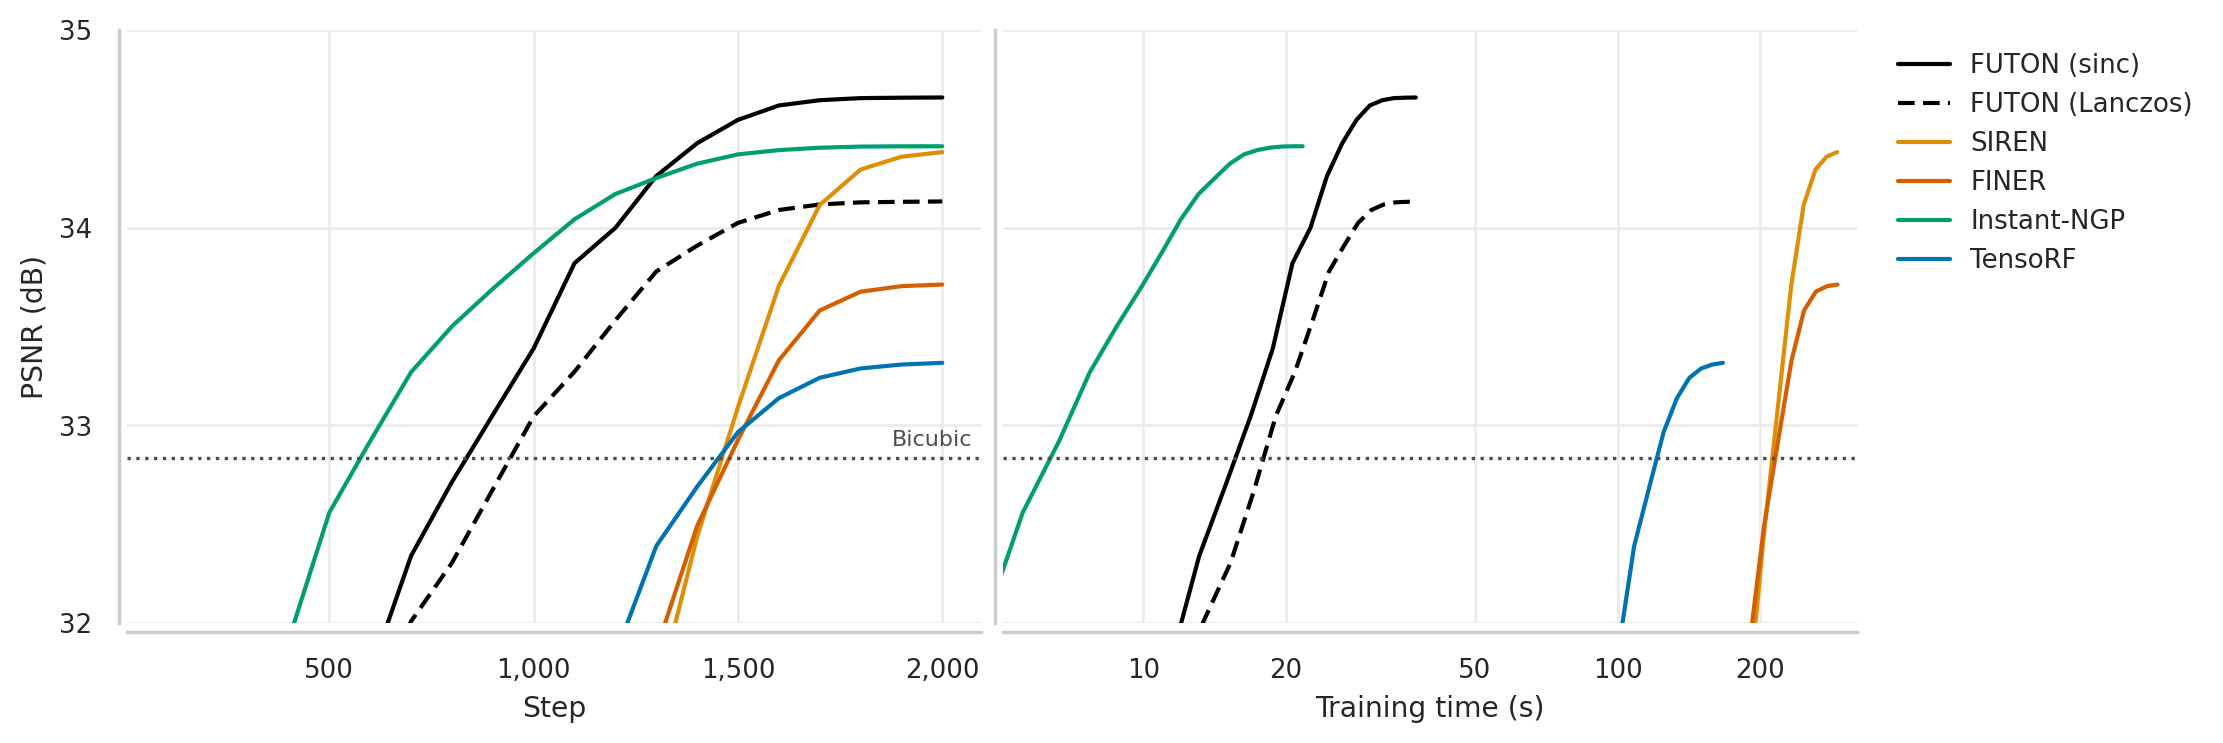

In [10]:
records = pd.DataFrame(
    {
        "Model": name,
        "Step": entry["epoch"],
        "Time (s)": entry["elapsed"],
        "PSNR (dB)": entry["eval"]["psnr"],
    }
    for name, result in results.items()
    for entry in result["history"]
    if "eval" in entry
)

order = [model for model in PALETTE if model in set(records["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, x in zip(axes, ("Step", "Time (s)")):
    sns.lineplot(
        records,
        x=x,
        y="PSNR (dB)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        dashes=DASHES,
        legend=ax is axes[1],
        ax=ax,
    )
    ax.axhline(bicubic, color=".3", linestyle=":", linewidth=1.2)
    if ax is axes[0]:
        ax.annotate(
            "Bicubic",
            (1, bicubic),
            xycoords=("axes fraction", "data"),
            xytext=(-3, 3),
            textcoords="offset points",
            ha="right",
            va="bottom",
            fontsize=8,
            color=".3",
        )
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
final = records.groupby("Model")["PSNR (dB)"].last()
low, high = min(final.min(), bicubic), max(records["PSNR (dB)"].max(), bicubic)
margin = 0.05 * (high - low)  # so that no curve ends on the frame
metric_axis(axes[0], "PSNR (dB)", low - margin, high + margin)
shown = records["PSNR (dB)"] >= axes[0].get_ylim()[0]  # the evaluations in view
time_axis(axes[1], records.loc[shown, "Time (s)"])

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Summary

Throughput is the median rate of the evaluations, which reconstruct the whole
HR image, and inference memory their median peak; training memory is the peak
of training. Bicubic interpolation's throughput is that of PIL's resize, and it
has no training, so the plot shows it as the dotted level. In each column the
best value is bold and the second underlined.

In [11]:
rows = []
for name, result in results.items():
    evaluations = [entry["eval"] for entry in result["history"] if "eval" in entry]
    duration = np.median([e["duration"] for e in evaluations])
    memory = np.median([e["peak_memory"] for e in evaluations])
    rows.append(
        {
            "Model": name,
            "Params (k)": result["config"]["num_params"] / 1e3,
            "Training time (s)": result["history"][-1]["elapsed"],
            "Training memory (MB)": result["config"]["peak_memory"] / 1e6,
            "Throughput (MPix/s)": H * W / duration / 1e6,
            "Inference memory (MB)": memory / 1e6,
            "PSNR (dB)": evaluations[-1]["psnr"],
            "SSIM": evaluations[-1]["ssim"],
            "LPIPS": evaluations[-1]["lpips"],
        }
    )
rows.append(
    {
        "Model": "Bicubic",
        "Params (k)": 0.0,
        "Throughput (MPix/s)": H * W / upsampling / 1e6,
        "PSNR (dB)": bicubic,
        "SSIM": METRICS["ssim"](upsampled, original),
        "LPIPS": METRICS["lpips"](upsampled, original),
    }
)
summary = pd.DataFrame(rows).sort_values("PSNR (dB)", ascending=False)

formats = {
    "Params (k)": "{:.1f}",
    "Training time (s)": "{:.1f}",
    "Training memory (MB)": "{:.0f}",
    "Throughput (MPix/s)": "{:.1f}",
    "Inference memory (MB)": "{:.0f}",
    "PSNR (dB)": "{:.2f}",
    "SSIM": "{:.3f}",
    "LPIPS": "{:.3f}",
}
better = {
    "Training time (s)": "lower",
    "Training memory (MB)": "lower",
    "Throughput (MPix/s)": "higher",
    "Inference memory (MB)": "lower",
    "PSNR (dB)": "higher",
    "SSIM": "higher",
    "LPIPS": "lower",
}
table(summary, formats, better)

Model,Params (k),Training time (s),Training memory (MB),Throughput (MPix/s),Inference memory (MB),PSNR (dB),SSIM,LPIPS
FUTON (sinc),499.8,37.6,830,38.1,700,34.66,0.953,0.240
Instant-NGP,505.2,21.7,432,60.6,280,34.41,0.949,0.232
SIREN,500.6,290.3,3837,6.2,884,34.38,0.948,0.233
FUTON (Lanczos),499.8,37.8,830,38.1,702,34.13,0.927,0.313
FINER,500.6,290.8,3837,6.2,884,33.71,0.925,0.295
TensoRF,500.4,166.7,2378,13.7,892,33.32,0.943,0.267
Bicubic,0.0,,,205.5,,32.83,0.947,0.258


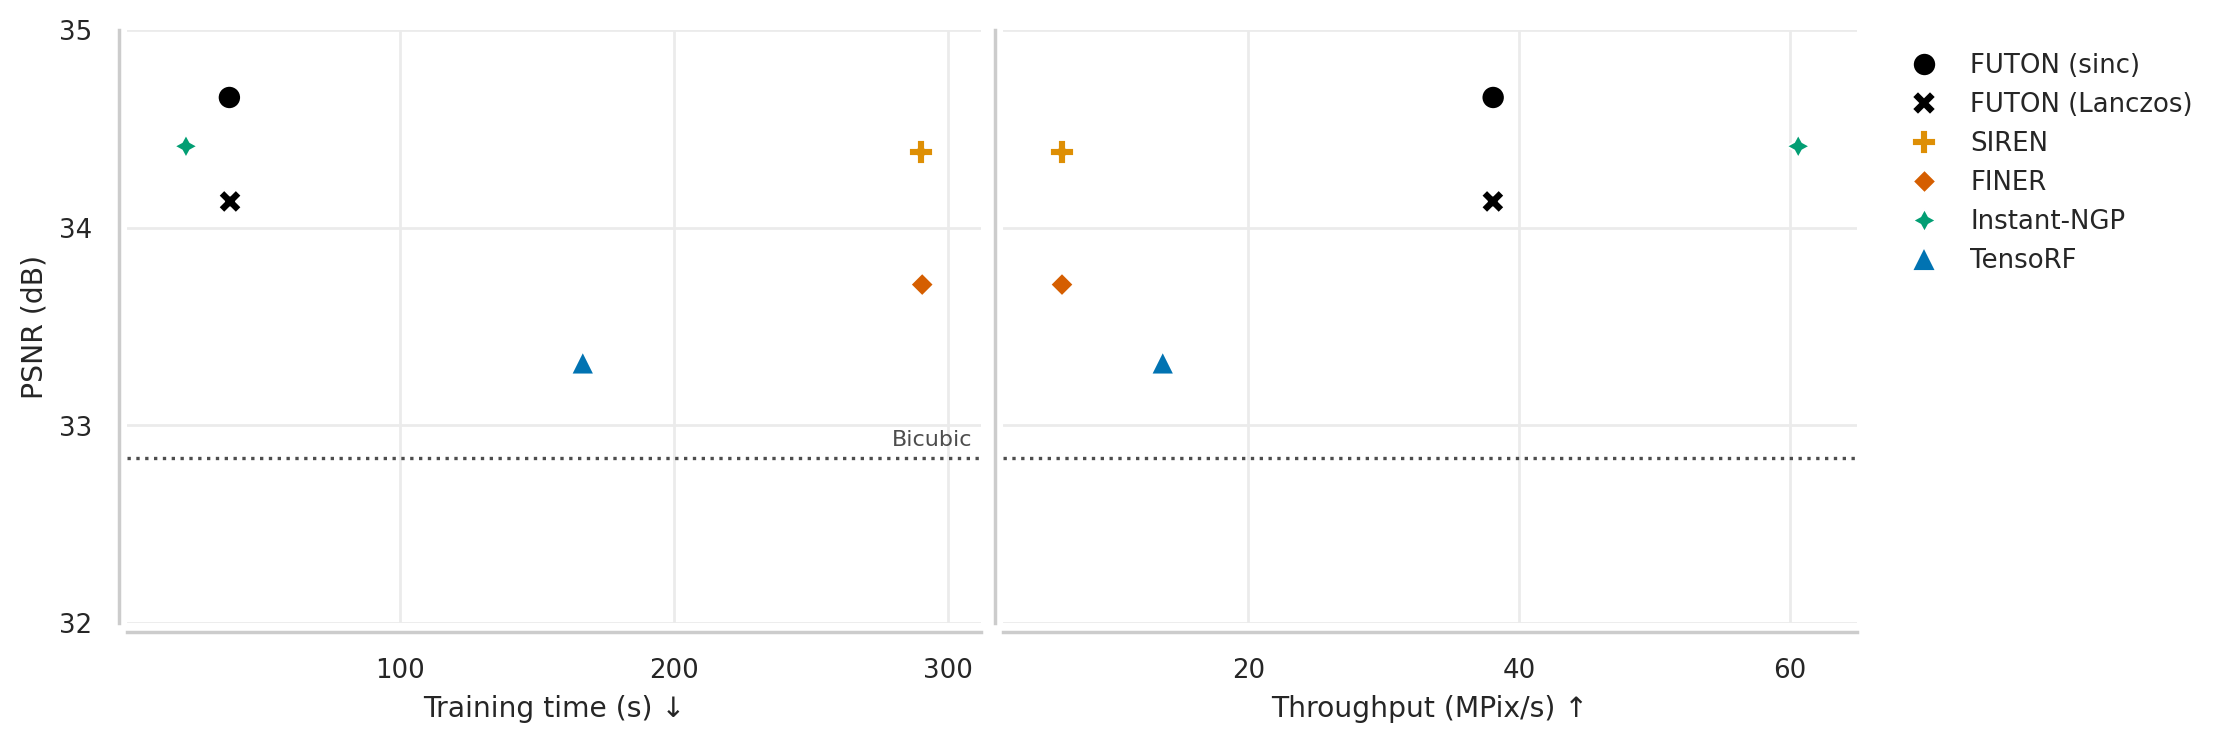

In [12]:
trained = summary[summary["Model"].isin(results)]  # the fields

order = [model for model in PALETTE if model in set(trained["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, cost in zip(axes, ("Training time (s)", "Throughput (MPix/s)")):
    sns.scatterplot(
        trained,
        x=cost,
        y="PSNR (dB)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        markers=MARKERS,
        s=70,
        legend=ax is axes[1],
        ax=ax,
    )
    ax.axhline(bicubic, color=".3", linestyle=":", linewidth=1.2)
    if ax is axes[0]:
        ax.annotate(
            "Bicubic",
            (1, bicubic),
            xycoords=("axes fraction", "data"),
            xytext=(-3, 3),
            textcoords="offset points",
            ha="right",
            va="bottom",
            fontsize=8,
            color=".3",
        )
    ax.margins(x=0.08)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].set_xlabel("Training time (s) ↓")
axes[1].set_xlabel("Throughput (MPix/s) ↑")
low = min(trained["PSNR (dB)"].min(), bicubic)
high = max(trained["PSNR (dB)"].max(), bicubic)
metric_axis(axes[0], "PSNR (dB)", low - 0.08 * (high - low), high + 0.08 * (high - low))

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Qualitative Comparison

The butterfly's head in every reconstruction, titled with its PSNR on the whole
image, and beneath, the error of each, averaged over the colour channels, on
one scale. The antennae are thinner than an LR pixel, so what a model draws
there comes from its inductive bias.

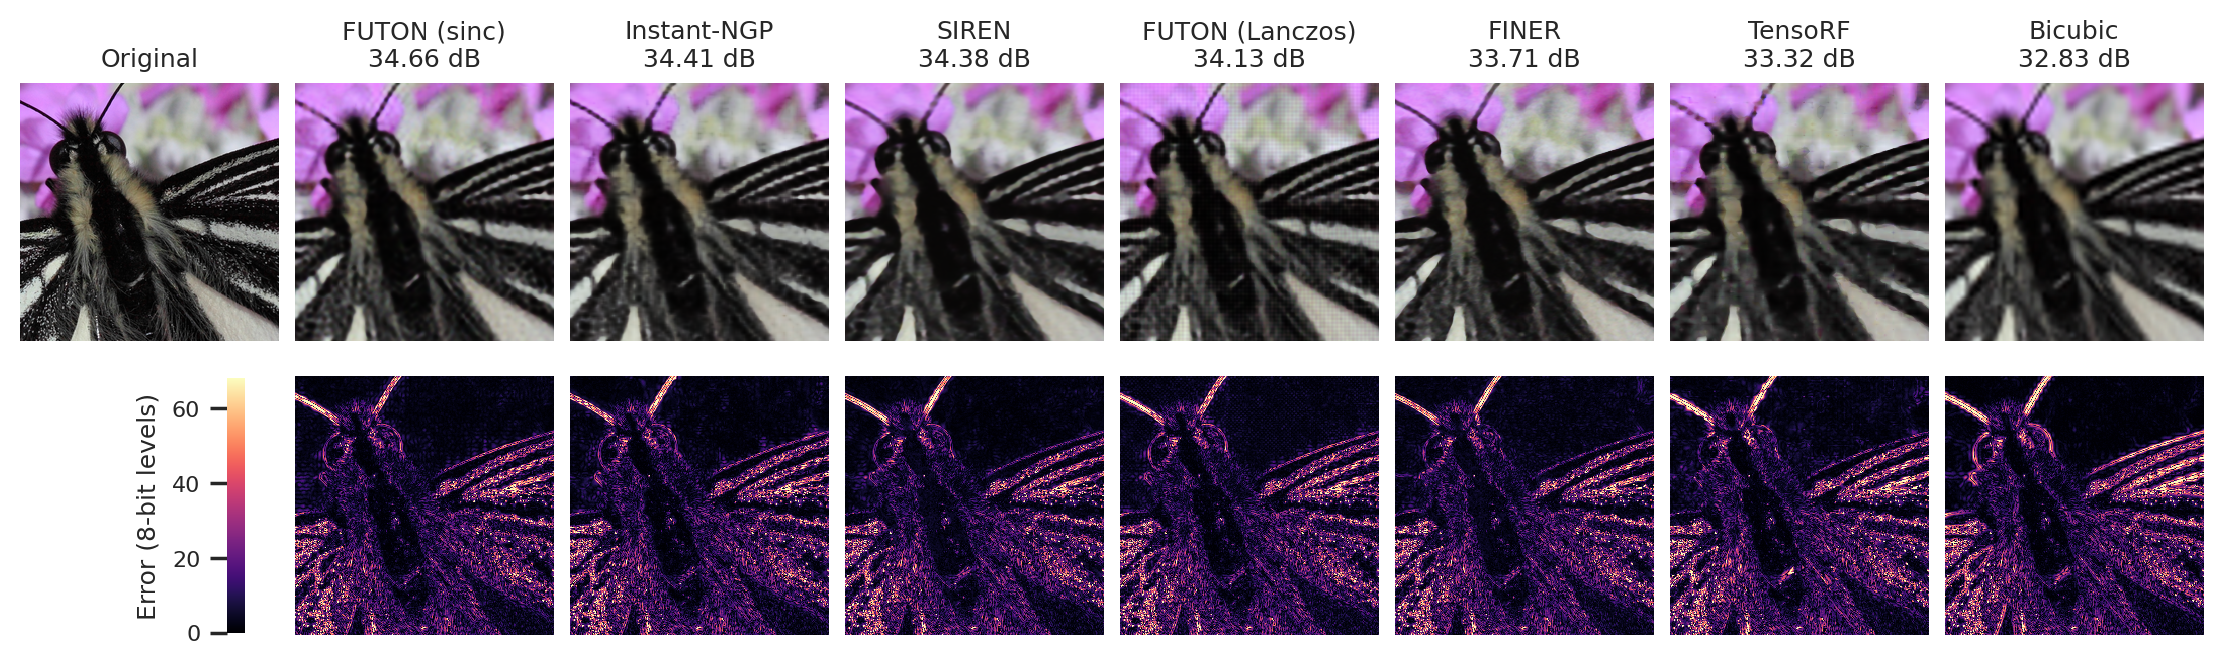

In [13]:
reconstructions = {name: result["reconstruction"] for name, result in results.items()}
reconstructions["Bicubic"] = upsampled
pixels = {
    name: image.permute(1, 2, 0).numpy() for name, image in reconstructions.items()
}
reference = original.permute(1, 2, 0).numpy()

crops = [("Original", reference[CROP])] + [
    (f"{name}\n{psnr:.2f} dB", pixels[name][CROP])
    for name, psnr in zip(summary["Model"], summary["PSNR (dB)"])
]
compare(crops, "Error (8-bit levels)")
plt.show()